# Segmenting point clouds into a sphere and planes

The input is a PCD frame with 3D points. The aim is to pick out one sphere, find the flat surfaces around it, and save the points with new colors in a PLY file. I'm using RANSAC for both shapes.


## Settings

These are the settings for the initial experiments. Later in the notebook, the final pipeline estimates the distance tolerances from each frame and removes the four-plane limit.


In [23]:
INPUT_FRAME = "Frame8078.pcd"          # None runs all PCD files; otherwise give one filename.
MAX_PLANES = 4              # Initial tests use four; None removes the cap.
PLANE_TOLERANCE_MM = 6.0    # Plane inlier distance, in mm.
MIN_PLANE_FRACTION = 0.03   # Minimum fraction of points needed for a plane.
RANSAC_TRIALS = 150         # Three-point attempts per plane.
RANDOM_SEED = 42            # Keeps random sampling reproducible.
SPHERE_TRIALS = 800         # Four-point sphere attempts.
SPHERE_TOLERANCE_MM = 5.0   # Sphere inlier distance, in mm.

## 1. Reading the PCD file

I read the header to locate `x`, `y` and `z` and ignore the other fields. Points with invalid values or nonpositive depth are left out.


In [24]:
import os
import math
import numpy as np

def read_pcd(file_path, filter_zeros=True):
    """Read XYZ columns from an ASCII PCD file."""
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"File not found: {file_path}")
        
    header = {}
    data_started = False
    points_list = []
    
    with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
                
            if not data_started:
                tokens = line.split()
                keyword = tokens[0].upper()
                if keyword == 'DATA':
                    header['DATA'] = tokens[1] if len(tokens) > 1 else 'ascii'
                    if header['DATA'].lower() != 'ascii':
                        raise ValueError("Expected an ASCII PCD file.")
                    fields = header.get('FIELDS', [])
                    counts = list(map(int, header.get('COUNT', ['1'] * len(fields))))
                    columns = [sum(counts[:fields.index(axis)]) for axis in ('x', 'y', 'z')]
                    data_started = True
                else:
                    header[keyword] = tokens[1:]
            else:
                parts = line.split()
                points_list.append([float(parts[i]) for i in columns])
                    
    points = np.array(points_list, dtype=np.float64).reshape(-1, 3)
    raw_count = len(points)
    
    if filter_zeros and len(points) > 0:
        valid_mask = np.isfinite(points).all(axis=1) & (points[:, 2] > 0.0) & (np.linalg.norm(points, axis=1) > 1e-3)
        points = points[valid_mask]
    
    return points, header, raw_count

In [25]:
from pathlib import Path

folder = Path.cwd()
if (folder / "FIRST_ASSIGNMENT" / "Assignment.ipynb").is_file():
    folder = folder / "FIRST_ASSIGNMENT"

if INPUT_FRAME is None:
    frame_paths = sorted(folder.glob("*.pcd"))
else:
    path = Path(INPUT_FRAME)
    frame_paths = [path if path.is_file() else folder / path]

if not frame_paths:
    raise FileNotFoundError(f"No PCD files found in {folder}")
print(f"Selected {len(frame_paths)} frame(s).")

Selected 1 frame(s).


## 2. Quick check: distance from a point to a plane

Before doing RANSAC, check the distance formula on a simple plane at `z = 500` mm. The test point is 2 mm away, so a 3 mm cutoff should accept it.


In [26]:
# A, B and C lie on z = 500 and are not on one line.
A = np.array([10, 20, 500])
B = np.array([30, 20, 500])
C = np.array([10, 50, 500])

# Q is 2 mm away from that plane.
Q = np.array([200, 100, 498])

normal = np.cross(B - A, C - A)
unit_normal = normal / np.linalg.norm(normal)
distance_mm = abs(np.dot(Q - A, unit_normal))

# Check with a 3 mm cutoff.
tolerance_mm = 3

print(f"Distance to plane: {distance_mm:g} mm")
print(f"Within tolerance: {distance_mm <= tolerance_mm}")

Distance to plane: 2 mm
Within tolerance: True


## 3. Plane RANSAC

As in the lab:
1. sample three points, 
2. fit a plane, 
3. count how many points fall near it 

keep the candidate with the most inliers, label those points, and run the search again on what is left.

---

The distance cutoff matters: 
- too small misses noisy parts of a wall; 
- too large can pull in points from other surfaces. 

Removing inliers also doesn't completely prevent the same physical wall from being detected twice.


In [27]:
def find_plane(cloud, tolerance_mm, trials, rng):
    """Find the sampled plane with the most inliers."""
    best_plane = None
    best_mask = np.zeros(len(cloud), dtype=bool)
    best_count = 0

    for _ in range(trials):
        a, b, c = cloud[rng.choice(len(cloud), size=3, replace=False)]
        normal = np.cross(b - a, c - a)
        length = np.linalg.norm(normal)
        
        if length < 1e-10:
            continue
        
        normal = normal / length
        offset = normal @ a
        mask = np.abs(cloud @ normal - offset) <= tolerance_mm
        count = np.count_nonzero(mask)
        
        if count > best_count:
            best_plane = (normal, offset)
            best_mask = mask
            best_count = count

    return best_plane, best_mask

In [28]:
def segment_planes(points, sphere_mask=None, tolerance_mm=None, max_planes=MAX_PLANES, refine=False):
    if tolerance_mm is None:
        tolerance_mm = PLANE_TOLERANCE_MM
    
    rng = np.random.default_rng(RANDOM_SEED)
    plane_labels = np.zeros(len(points), dtype=int)
    
    if sphere_mask is not None:
        plane_labels[sphere_mask] = -1  # Exclude sphere points from the plane search.
    
    remaining = np.flatnonzero(plane_labels == 0)
    planes = []
    min_points = max(3, math.ceil(MIN_PLANE_FRACTION * len(points)))

    while len(remaining) >= min_points and (max_planes is None or len(planes) < max_planes):
        plane, mask = find_plane(points[remaining], tolerance_mm, RANSAC_TRIALS, rng)
        count = np.count_nonzero(mask)
        
        if count < min_points:
            break
        
        if refine:
            cloud = points[remaining]
            normal, offset = refit_plane(cloud[mask])
            refined_mask = np.abs(cloud @ normal - offset) <= tolerance_mm
        
            if np.count_nonzero(refined_mask) >= min_points:
                plane, mask = (normal, offset), refined_mask
        
        planes.append(plane)
        plane_labels[remaining[mask]] = len(planes)
        remaining = remaining[~mask]
        
    return planes, plane_labels

frame_results = {}

for path in frame_paths:
    points, header, raw_count = read_pcd(path)
    planes, labels = segment_planes(points)
    frame_results[path.name] = (points, planes, labels)
    
    print(f"{path.name}: {len(points):,}/{raw_count:,} valid points, {len(planes)} planes")

Frame8078.pcd: 217,088/217,088 valid points, 4 planes


## 4. Looking at the plane results

I use OpenCV to draw the labels in two ways: 
- `x/z` against `y/z` for a camera-like view, 
- `z` against `y` for a side view.


In [29]:
import cv2

# The notebook previews are ordinary OpenCV images. Jupyter displays PNGs
# returned by this method, without adding another plotting library.
class Preview:
    def __init__(self, bgr_image):
        self.bgr_image = bgr_image

    def _repr_png_(self):
        ok, encoded = cv2.imencode(".png", self.bgr_image)
        if not ok:
            raise ValueError("Could not encode preview image")
        return encoded.tobytes()


# These colors are for the early plane-only comparison plots.
# The final PLY uses label_colors(), defined later in the notebook.
PLANE_PREVIEW_COLORS = np.array([
    [31, 119, 180], [174, 199, 232], [255, 127, 14],
    [255, 187, 120], [44, 160, 44], [152, 223, 138],
    [214, 39, 40], [255, 152, 150], [148, 103, 189],
    [197, 176, 213], [140, 86, 75], [196, 156, 148],
    [227, 119, 194], [247, 182, 210], [127, 127, 127],
    [199, 199, 199], [188, 189, 34], [219, 219, 141],
    [23, 190, 207], [158, 218, 229]
], dtype=np.uint8)


def plane_preview_colors(labels):
    rgb = np.full((len(labels), 3), 211, dtype=np.uint8)
    for label in np.unique(labels):
        if label > 0:
            rgb[labels == label] = PLANE_PREVIEW_COLORS[(label - 1) % len(PLANE_PREVIEW_COLORS)]
    return rgb


def plot_panel(points, rgb, view="camera", title="", width=510, height=360, limits=None):
    """Draw a scatter-style view using RGB point colors and an OpenCV canvas."""
    image = np.full((height, width, 3), 255, dtype=np.uint8)
    left, right, top, bottom = 77, width - 18, 40, height - 48
    if view == "camera":
        x, y = points[:, 0] / points[:, 2], points[:, 1] / points[:, 2]
        xlabel, ylabel = "x / z", "y / z"
    elif view == "side":
        x, y = points[:, 2], points[:, 1]
        xlabel, ylabel = "Depth z (mm)", "Height y (mm)"
    else:
        raise ValueError(f"Unknown view: {view}")

    if limits is None:
        xmin, xmax = float(x.min()), float(x.max())
        ymin, ymax = float(y.min()), float(y.max())
    else:
        xmin, xmax, ymin, ymax = limits

    # One scale for both axes (as with aspect='equal' in Matplotlib).
    units_per_pixel = max((xmax - xmin) / max(right - left, 1),
                          (ymax - ymin) / max(bottom - top, 1), 1e-12) * 1.04
    cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2
    sx = np.rint((x - cx) / units_per_pixel + (left + right) / 2).astype(np.int32)
    sy = np.rint((top + bottom) / 2 - (y - cy) / units_per_pixel).astype(np.int32)
    inside = (sx >= left) & (sx <= right) & (sy >= top) & (sy <= bottom)
    colors_bgr = np.asarray(rgb, dtype=np.uint8)[:, ::-1]

    # Leave sphere pixels on top of the background and plane measurements.
    yellow = np.all(np.asarray(rgb) == [255, 255, 0], axis=1)
    for choose in (inside & ~yellow, inside & yellow):
        image[sy[choose], sx[choose]] = colors_bgr[choose]

    cv2.rectangle(image, (left, top), (right, bottom), (170, 170, 170), 1)
    cv2.putText(image, title, (left, 24), cv2.FONT_HERSHEY_SIMPLEX,
                0.55, (45, 45, 45), 1, cv2.LINE_AA)
    cv2.putText(image, xlabel, ((left + right) // 2 - 42, height - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.41, (70, 70, 70), 1, cv2.LINE_AA)
    # Rotate the y-axis label, so it cannot overlap the plot title.
    font = cv2.FONT_HERSHEY_SIMPLEX
    text_size, baseline = cv2.getTextSize(ylabel, font, 0.40, 1)
    label_strip = np.full((text_size[1] + baseline + 8,
                           text_size[0] + 12, 3), 255, dtype=np.uint8)
    cv2.putText(label_strip, ylabel, (5, text_size[1] + 3), font,
                0.40, (70, 70, 70), 1, cv2.LINE_AA)
    label_strip = cv2.rotate(label_strip, cv2.ROTATE_90_COUNTERCLOCKWISE)
    label_y = (top + bottom - label_strip.shape[0]) // 2
    image[label_y:label_y + label_strip.shape[0],
          3:3 + label_strip.shape[1]] = label_strip

    # Axis values help make the plots useful for comparing different frames.
    for fraction in (0.0, 0.5, 1.0):
        xt = int(left + fraction * (right - left))
        yt = int(bottom - fraction * (bottom - top))
        value_x = cx + (xt - (left + right) / 2) * units_per_pixel
        value_y = cy + ((top + bottom) / 2 - yt) * units_per_pixel
        cv2.line(image, (xt, bottom), (xt, bottom + 4), (120, 120, 120), 1)
        cv2.line(image, (left - 4, yt), (left, yt), (120, 120, 120), 1)
        fmt = ".2f" if view == "camera" else ".0f"
        cv2.putText(image, format(value_x, fmt), (xt - 18, bottom + 18),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.32, (90, 90, 90), 1, cv2.LINE_AA)
        cv2.putText(image, format(value_y, fmt), (24, yt + 4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.32, (90, 90, 90), 1, cv2.LINE_AA)
    return image


def combine_panels(panels, title="", columns=2, legend=None):
    """Arrange OpenCV panels with an optional color legend."""
    if not panels:
        raise ValueError("No panels")
    panel_h, panel_w = panels[0].shape[:2]
    rows = math.ceil(len(panels) / columns)
    gap, margin, title_space = 12, 12, 37
    legend_width = 210 if legend else 0
    width = margin * 2 + columns * panel_w + (columns - 1) * gap + legend_width
    height = margin * 2 + title_space + rows * panel_h + (rows - 1) * gap
    result = np.full((height, width, 3), 255, dtype=np.uint8)
    cv2.putText(result, title, (margin + 8, 27), cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (30, 30, 30), 2, cv2.LINE_AA)
    for index, panel in enumerate(panels):
        y0 = margin + title_space + (index // columns) * (panel_h + gap)
        x0 = margin + (index % columns) * (panel_w + gap)
        result[y0:y0 + panel_h, x0:x0 + panel_w] = panel
    if legend:
        x0 = width - legend_width + 10
        y0 = margin + title_space + 18
        cv2.putText(result, "Labels", (x0, y0 - 12), cv2.FONT_HERSHEY_SIMPLEX,
                    0.48, (60, 60, 60), 1, cv2.LINE_AA)
        for k, (name, rgb_color) in enumerate(legend):
            y = y0 + k * 25
            cv2.rectangle(result, (x0, y), (x0 + 13, y + 13),
                          tuple(int(v) for v in rgb_color[::-1]), -1)
            cv2.putText(result, str(name), (x0 + 21, y + 11),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.42, (55, 55, 55), 1, cv2.LINE_AA)
    return result

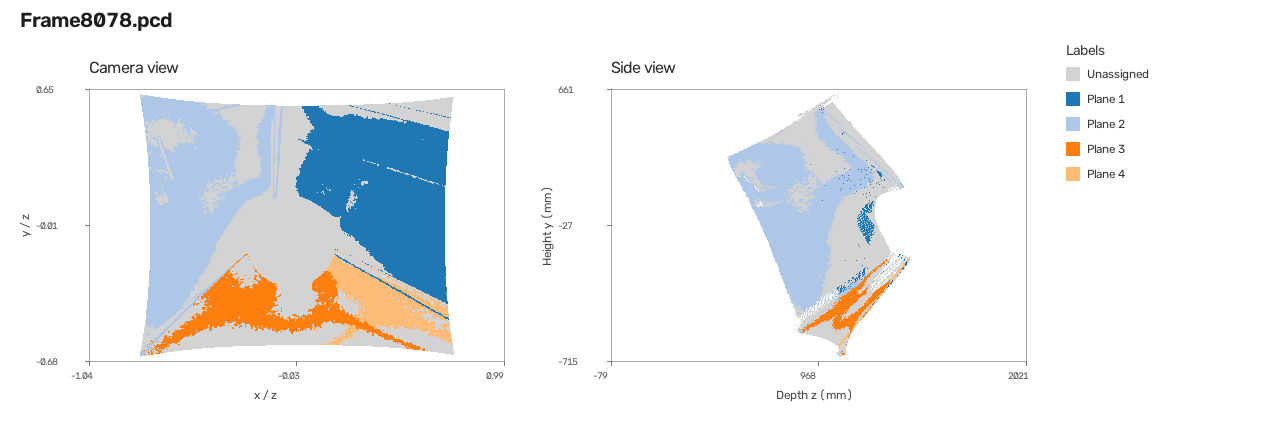

In [30]:
for filename, (points, planes, plane_labels) in frame_results.items():
    rgb = plane_preview_colors(plane_labels)
    views = [plot_panel(points, rgb, "camera", "Camera view"),
             plot_panel(points, rgb, "side", "Side view")]
    legend = [("Unassigned", np.array([211, 211, 211], dtype=np.uint8))]
    legend += [(f"Plane {i}", PLANE_PREVIEW_COLORS[(i - 1) % 20])
               for i in range(1, len(planes) + 1)]
    display(Preview(combine_panels(views, filename, legend=legend)))

## 5. Sphere fit from four points

This example checks the sphere equations before using them inside RANSAC. The four points are all 5 mm from the known center.


In [31]:
def sphere_from_four(sample):
    origin = sample[0]
    delta = sample[1:] - origin
    try:
        shift = np.linalg.solve(2 * delta, np.sum(delta ** 2, axis=1))
    except np.linalg.LinAlgError:
        return None
    return origin + shift, np.linalg.norm(shift)

# Test with a known 5 mm sphere.
sample = np.array([[15, 20, 500], [10, 25, 500], [10, 20, 505], [5, 20, 500]])
center, radius = sphere_from_four(sample)
print(f"Center: {center} mm, radius: {radius:g} mm")

Center: [ 10.  20. 500.] mm, radius: 5 mm


## 6. Sphere RANSAC

I use up to 6,000 points for scoring candidates so the search stays manageable. For each attempt, I take an anchor and draw four points from its neighborhood. Nearby points are more likely to be from the same object. I also reject spheres that are too large relative to the scene: a huge sphere can resemble a flat wall.

To count an inlier, the point must be close to the candidate radius. I also keep only the camera-facing side, assuming the camera is at `(0, 0, 0)`. This is why the normal/viewing-direction check appears in `visible_sphere_inliers()`.

### Refining the sphere after RANSAC

The winning candidate comes from four measured points, which may be noisy. Once I have its inliers from the whole frame, `refine_sphere()` uses those points to improve the center and radius. It minimizes the squared difference between each point's distance to the center and the fitted radius, using Gauss–Newton steps written with NumPy. Finally, I calculate the inlier mask again using the refined sphere.

This improves the fit to the selected points. It doesn't fix a wrong sphere if the RANSAC search picked the wrong surface in the first place.


In [32]:
def visible_sphere_inliers(points, center, radius, tolerance_mm):
    offsets = points - center
    errors = np.abs(np.linalg.norm(offsets, axis=1) - radius)
    
    # Assume the camera is at the coordinate origin.
    facing_camera = np.sum(offsets * points, axis=1) <= 0
    
    return (errors <= tolerance_mm) & facing_camera


def refine_sphere(inliers, center, radius, iterations=10):
    """Use Gauss-Newton to reduce radial errors on the sphere inliers."""
    center = np.asarray(center, dtype=float).copy()
    radius = float(radius)
    
    if len(inliers) < 4:
        return center, radius

    for _ in range(iterations):
        offsets = inliers - center
        distances = np.linalg.norm(offsets, axis=1)
        valid = distances > 1e-12  # The radial direction is undefined at the center.
        if np.count_nonzero(valid) < 4:
            break

        residuals = distances[valid] - radius
        jacobian = np.column_stack((
            -offsets[valid] / distances[valid, None],
            -np.ones(np.count_nonzero(valid))
        ))
        
        # Solve for changes in the three center coordinates and the radius.
        step, *_ = np.linalg.lstsq(jacobian, -residuals, rcond=None)
        new_center = center + step[:3]
        new_radius = radius + step[3]
        
        if not np.all(np.isfinite(new_center)) or not np.isfinite(new_radius) or new_radius <= 0:
            break
        
        # Shorten the step if it makes the fit worse.
        old_sse = np.sum(residuals ** 2)
        fraction = 1.0
        accepted = False
        
        for _ in range(10):
            candidate_center = center + fraction * step[:3]
            candidate_radius = radius + fraction * step[3]
        
            if candidate_radius > 0:
                candidate_residuals = np.linalg.norm(inliers[valid] - candidate_center, axis=1) - candidate_radius
        
                if np.sum(candidate_residuals ** 2) <= old_sse:
                    center, radius = candidate_center, candidate_radius
                    accepted = True
                    break
            fraction *= 0.5
        
        if not accepted or np.linalg.norm(fraction * step) < 1e-5:
            break

    return center, radius


def find_sphere(points, tolerance_mm=SPHERE_TOLERANCE_MM):
    rng = np.random.default_rng(RANDOM_SEED)
    sample = points[rng.choice(len(points), min(6000, len(points)), replace=False)]
    scene_width = np.linalg.norm(np.ptp(sample, axis=0))
    best_count = 0
    best = None
    
    for _ in range(SPHERE_TRIALS):
        anchor = sample[rng.integers(len(sample))]
        nearby = sample[np.linalg.norm(sample - anchor, axis=1) < scene_width / 10]
    
        if len(nearby) < 4:
            continue
        sphere = sphere_from_four(nearby[rng.choice(len(nearby), 4, replace=False)])
    
        if sphere is None:
            continue
        center, radius = sphere
    
        if radius > scene_width / 4:
            continue
        count = np.count_nonzero(visible_sphere_inliers(sample, center, radius, tolerance_mm))
    
        if count > best_count:
            best_count = count
            best = sphere

    if best is None:
        raise ValueError("Could not fit a sphere to this frame.")
   
    center, radius = best
   
    # Refit using the full-cloud inliers, then check membership again.
    initial_mask = visible_sphere_inliers(points, center, radius, tolerance_mm)
    center, radius = refine_sphere(points[initial_mask], center, radius)
    final_mask = visible_sphere_inliers(points, center, radius, tolerance_mm)
   
    return center, radius, final_mask


In [33]:
sphere_results = {}

for filename, (points, _, _) in frame_results.items():
    center, radius, mask = find_sphere(points)
    sphere_results[filename] = (center, radius, mask)
    print(f"{filename}: radius {radius:.1f} mm, {mask.sum():,} sphere points")

Frame8078.pcd: radius 203.5 mm, 13,445 sphere points


### Check the detected sphere

The yellow points are the sphere inliers. The grey background shows depth. I'm checking whether the yellow region looks round and whether it spills into the wall.


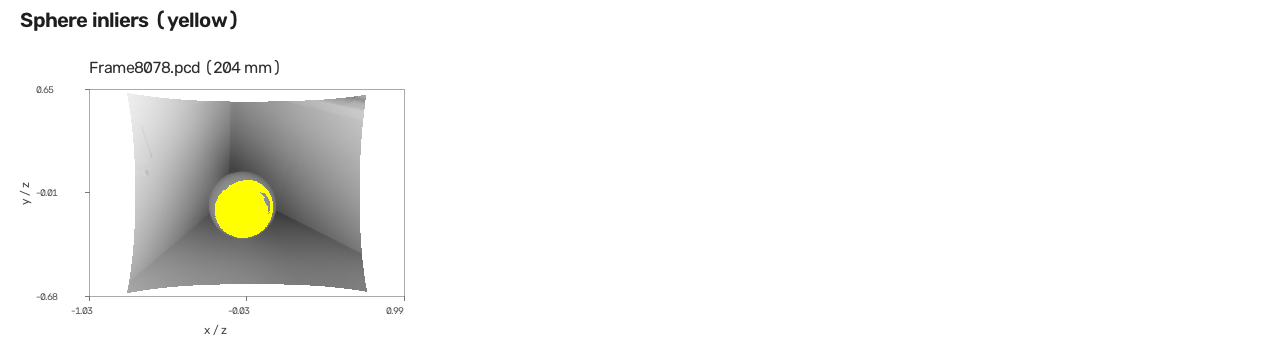

In [34]:
# Each panel shows the same camera projection with the sphere in yellow.
sphere_panels = []
for filename, (points, _, _) in frame_results.items():
    center, radius, mask = sphere_results[filename]
    z = points[:, 2]
    scaled_depth = (z - z.min()) / max(np.ptp(z), 1e-12)
    grey = (238 - scaled_depth * 180).astype(np.uint8)
    rgb = np.repeat(grey[:, None], 3, axis=1)
    rgb[mask] = [255, 255, 0]
    sphere_panels.append(plot_panel(points, rgb, "camera",
                                   f"{filename} ({radius:.0f} mm)",
                                   width=410, height=295))
display(Preview(combine_panels(sphere_panels, "Sphere inliers (yellow)", columns=3)))

## 7. Put the sphere and planes together

Some points near the ball and wall could pass both distance tests. I mark the sphere first (`-1`) and leave those points out of the plane search. Planes use labels `1, 2, ...`; unassigned points have label `0`. Keeping the original point order also makes it straightforward to attach the RGB values when exporting.


In [35]:
from colorsys import hsv_to_rgb

def label_colors(plane_count):
    # Label 0 is grey; -1 indexes the last palette entry (yellow).
    palette = [[160, 160, 160]]
    for i in range(plane_count):
        hue = (0.6 + i * 0.618) % 1
        palette.append([round(255 * v) for v in hsv_to_rgb(hue, 0.8, 0.85)])
    palette.append([255, 255, 0])
    return np.array(palette, dtype=np.uint8)

combined_results = {}
for filename, (points, _, _) in frame_results.items():
    _, _, sphere_mask = sphere_results[filename]
    planes, labels = segment_planes(points, sphere_mask)
    colors = label_colors(len(planes))[labels]
    combined_results[filename] = (planes, labels, colors)

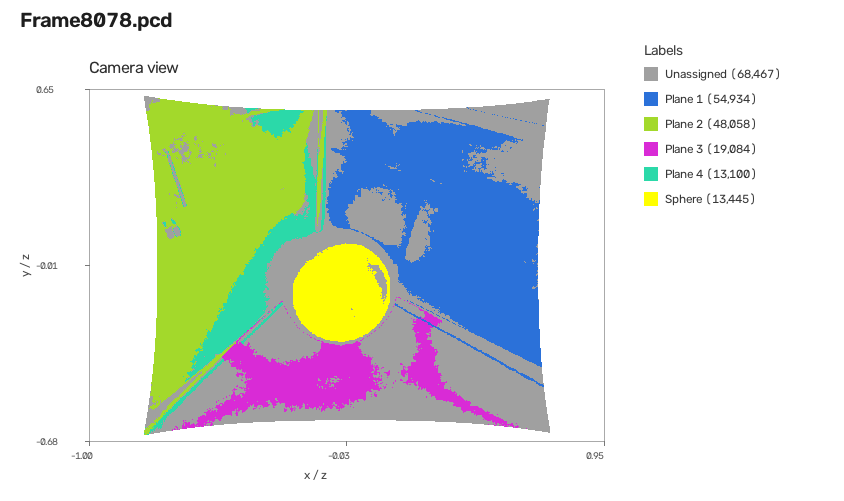

In [36]:
# Prefer Frame4994 for the detailed plot.
filename = "Frame4994.pcd" if "Frame4994.pcd" in combined_results else next(iter(combined_results))
points = frame_results[filename][0]
planes, labels, colors = combined_results[filename]
legend = []
for label in [0, *range(1, len(planes) + 1), -1]:
    count = int(np.count_nonzero(labels == label))
    if not count:
        continue
    name = {-1: "Sphere", 0: "Unassigned"}.get(label, f"Plane {label}")
    rgb = label_colors(len(planes))[label]
    legend.append((f"{name} ({count:,})", rgb))
view = plot_panel(points, colors, "camera", "Camera view", width=610, height=440)
display(Preview(combine_panels([view], filename, columns=1, legend=legend)))

### Comparing 3 mm and 6 mm for planes

I try both cutoffs on the same frame. A wider cutoff assigns more points, but that does not automatically mean a better segmentation. Plane numbers can refer to different surfaces between runs because each round depends on which points were removed earlier.


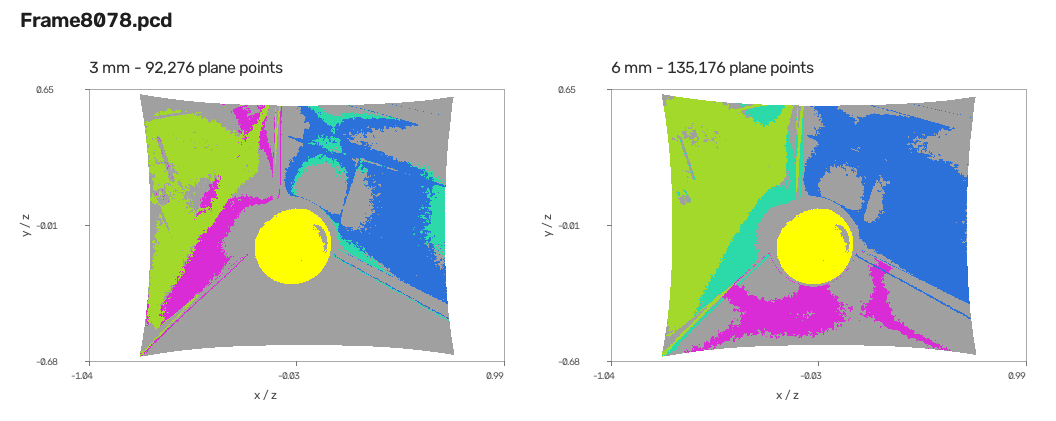

In [37]:
# Compare the two cutoffs on the same points and with the same axis limits.
points = frame_results[filename][0]
sphere_mask = sphere_results[filename][2]
views = []

for tolerance in (3.0, 6.0):
    models, trial_labels = segment_planes(points, sphere_mask, tolerance_mm=tolerance)
    rgb = label_colors(len(models))[trial_labels]
    assigned = np.count_nonzero(trial_labels > 0)
    views.append(plot_panel(points, rgb, "camera",
                            f"{tolerance:g} mm - {assigned:,} plane points"))
display(Preview(combine_panels(views, filename)))

In [38]:
# Count how much of each frame gets a plane label.
print(f"{'Frame':<17} {'3 mm':>8} {'6 mm':>8}")
for name, (cloud, _, _) in frame_results.items():
    sphere_mask = sphere_results[name][2]
    coverage = []
    for tolerance in (3.0, 6.0):
        _, labels = segment_planes(cloud, sphere_mask, tolerance_mm=tolerance)
        coverage.append(100 * np.mean(labels > 0))
    print(f"{name:<17} {coverage[0]:7.1f}% {coverage[1]:7.1f}%")

Frame                 3 mm     6 mm
Frame8078.pcd        42.5%    62.3%


In the initial four-plane experiment, 6 mm increased overall plane coverage from 39.6% to 59.9% on the 11 frames. Some wall patches became more complete, but I could still see multiple colors on a single surface in Frame4994. I kept 6 mm as the reference setting for these comparisons.

*These percentages are from the earlier experiment; rerunning after the sphere refinement may change them slightly.*


### What happens without the four-plane cap?

Here I let the support test decide when to stop instead of always taking four planes. A candidate needs inliers from at least 3% of the valid frame points. I keep the same 6 mm tolerance for this comparison.


In [39]:
for name, (cloud, _, _) in frame_results.items():
    sphere_mask = sphere_results[name][2]
    models, labels = segment_planes(cloud, sphere_mask, max_planes=None)
    extra = np.count_nonzero(labels > 4)
    print(f"{name}: {len(models)} plane candidates, {extra:,} points after plane 4")

Frame8078.pcd: 7 plane candidates, 30,910 points after plane 4


In the earlier run I got 6–8 plane candidates per frame, and overall coverage rose to 73.3%. That is more coverage, but not necessarily more real surfaces. For Frame4994, the eighth plane was nearly parallel to the first (about 0.5° apart), with its inlier centroid around 9.8 mm from plane 1. This looks like part of the same surface being picked up again.

*These notes describe the earlier experiment, not a fresh measurement after sphere refinement.*


## 8. Estimate tolerances and refit the planes

A fixed distance cutoff may not work equally well on every frame. To estimate the local noise, I take small neighborhoods, fit a plane to each one, and measure the spread of their residuals with the median absolute deviation (MAD). The factor 1.4826 gives a standard-deviation-like scale when the residuals are approximately normal.

In the final pipeline I use `4 × noise` for plane tolerance and `3.5 × noise` for sphere tolerance. Those multipliers are still choices I made; the distances themselves change from frame to frame.

I also refit each accepted plane using all its inliers, not just the three points that originally defined it. The eigenvector with the smallest spread gives the fitted normal, and I check the inliers once more.

In an earlier Frame4994 comparison at a fixed 6 mm, refitting changed eight candidates to six and reduced plane coverage from 151,168 to 144,567 points. With adaptive cutoffs it found eight candidates again. So the cutoff and refitting both affect what remains for later iterations.


In [40]:
def refit_plane(inliers):
    """Fit a plane through the inliers by finding their least-spread direction."""
    center = inliers.mean(axis=0)
    centered = inliers - center
    _, axes = np.linalg.eigh(centered.T @ centered)
    normal = axes[:, 0]  # Normal is the least-spread direction.
    
    return normal, normal @ center


def estimate_surface_noise(points):
    """Estimate a noise scale from small local patches."""
    rng = np.random.default_rng(RANDOM_SEED)
    sample = points[rng.choice(len(points), min(len(points), 10000), replace=False)]
    
    if len(sample) < 4:
        raise ValueError("At least four valid points are required.")
    
    scales = []
    
    for anchor in sample[rng.choice(len(sample), min(64, len(sample)), replace=False)]:
        distances = np.sum((sample - anchor) ** 2, axis=1)
        k = min(40, len(sample))
        patch = sample[np.argpartition(distances, k - 1)[:k]]
        normal, offset = refit_plane(patch)
        residuals = patch @ normal - offset
        mad = np.median(np.abs(residuals - np.median(residuals)))
        scales.append(1.4826 * mad)
    
    precision = np.finfo(float).eps * max(1.0, np.max(np.abs(sample))) * 32
    
    return max(np.median(scales), precision)

In [41]:
def segment_frame(points):
    noise = estimate_surface_noise(points)
    plane_tolerance = 4 * noise
    sphere_tolerance = 3.5 * noise
    _, _, sphere_mask = find_sphere(points, tolerance_mm=sphere_tolerance)
    planes, labels = segment_planes(points, sphere_mask, tolerance_mm=plane_tolerance,
                                   max_planes=None, refine=True)
    colors = label_colors(len(planes))[labels]
    
    return labels, colors, plane_tolerance, sphere_tolerance

for name, (cloud, _, _) in frame_results.items():
    labels, _, plane_tol, sphere_tol = segment_frame(cloud)
    print(f"{name}: plane {plane_tol:.2f} mm, sphere {sphere_tol:.2f} mm, "
          f"{labels.max()} plane candidates, {(labels == -1).sum():,} sphere points")

Frame8078.pcd: plane 4.36 mm, sphere 3.81 mm, 9 plane candidates, 12,011 sphere points


---


## 9. Exporting `main.py`

The notebook is for experimenting and checking plots. The next cells define the PLY writer and build a standalone script from the functions above.

Example command:

```bash
python main.py Frame4994.pcd Frame4994.ply
```


In [42]:
def write_ply(path, points, colors):
    header = ("ply\nformat ascii 1.0\n"
              f"element vertex {len(points)}\n"
              "property double x\nproperty double y\nproperty double z\n"
              "property uchar red\nproperty uchar green\nproperty uchar blue\nend_header")
    np.savetxt(path, np.column_stack((points, colors)), header=header, comments="",
               fmt="%.12g %.12g %.12g %d %d %d")

def main():
    import argparse
    parser = argparse.ArgumentParser(description="Color the sphere and planes in an ASCII PCD.")
    parser.add_argument("input_pcd")
    parser.add_argument("output_ply")
    args = parser.parse_args()
    points, _, _ = read_pcd(args.input_pcd)
    _, colors, plane_tol, sphere_tol = segment_frame(points)
    write_ply(args.output_ply, points, colors)
    print(f"Saved {len(points):,} points. Plane tolerance {plane_tol:.2f} mm, "
          f"sphere tolerance {sphere_tol:.2f} mm.")

In [43]:
import inspect

functions = [read_pcd, refit_plane, estimate_surface_noise, find_plane, segment_planes,
             sphere_from_four, refine_sphere, visible_sphere_inliers, find_sphere, label_colors,
             segment_frame, write_ply, main]
imports = "import math\nimport os\nfrom colorsys import hsv_to_rgb\n\nimport numpy as np"
settings = ["MAX_PLANES", "PLANE_TOLERANCE_MM", "MIN_PLANE_FRACTION", "RANSAC_TRIALS",
            "RANDOM_SEED", "SPHERE_TRIALS", "SPHERE_TOLERANCE_MM"]
constants = "\n".join(f"{name} = {globals()[name]!r}" for name in settings)
source = "\n\n\n".join([imports, constants, *(inspect.getsource(fn).rstrip() for fn in functions),
                         'if __name__ == "__main__":\n    main()'])
(folder / "main.py").write_text(source + "\n", encoding="utf-8")

10731

### Submission note

The assignment asks for a separate record of GenAI use. ChatGPT helped with notebook review and sphere least-squares refinement. The earlier notebook also marked the command-line export section as AI-assisted. Include an accurate record of these uses, with the relevant prompts and responses, in the separate file requested by the assignment.
